# 📊 Módulo 1 — Análisis Exploratorio de Datos (EDA)
**Proyecto:** Análisis de Sentimientos de Reseñas de Productos en Español (Opinómetro)  
**Dataset:** `SetFit/amazon_reviews_multi_es`  
**Archivo fuente:** `data/raw/train.jsonl`  
**Objetivo:** Conocer en profundidad las características estadísticas, léxicas y de calidad del conjunto de datos antes de aplicar el preprocesamiento NLP y el entrenamiento de modelos de Machine Learning.


## 1. Importación de librerías y configuración del entorno

In [1]:
import json
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("Librerías importadas correctamente.")


Matplotlib is building the font cache; this may take a moment.


Librerías importadas correctamente.


## 2. Carga e Inspección General del Dataset

Se carga el archivo `data/raw/train.jsonl` en formato JSON Lines.


In [2]:
# Rutas relativas robustas
ruta_dataset = Path("../data/raw/train.jsonl")
if not ruta_dataset.exists():
    ruta_dataset = Path("data/raw/train.jsonl")

print(f"Cargando dataset desde: {ruta_dataset.resolve()}")
df = pd.read_json(ruta_dataset, lines=True)

print(f"Dimensiones del dataset: {df.shape[0]:,} filas y {df.shape[1]} columnas.")
df.head()


Cargando dataset desde: D:\UAGRM\999 TOPICOS AVANZADOS DE PROGRAMACION\CritiqAI\data\raw\train.jsonl


Dimensiones del dataset: 200,000 filas y 4 columnas.


,id,text,label,label_text
0,es_0491108,Nada bueno se me fue ka pantalla en menos de 8...,0,0
1,es_0869872,"Horrible, nos tuvimos que comprar otro porque ...",0,0
2,es_0811721,Te obligan a comprar dos unidades y te llega s...,0,0
3,es_0359921,"No entro en descalificar al vendedor, solo pue...",0,0
4,es_0068940,Llega tarde y co la talla equivocada,0,0


### 2.1 Tipos de datos e información de columnas

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   id          200000 non-null  str  
 1   text        200000 non-null  str  
 2   label       200000 non-null  int64
 3   label_text  200000 non-null  int64
dtypes: int64(2), str(2)
memory usage: 6.1 MB


## 3. Calidad de Datos: Valores Faltantes, Espacios en Blanco y Duplicados

In [4]:
# 1. Valores nulos
nulos = df.isnull().sum()
print("--- Valores Nulos por Columna ---")
print(nulos)

# 2. Textos vacíos o compuestos únicamente de espacios
textos_vacios = (df['text'].str.strip() == '').sum()
print(f"\nTextos vacíos o sólo espacios: {textos_vacios}")

# 3. Duplicados por identificador único
duplicados_id = df['id'].duplicated().sum()
print(f"Identificadores duplicados (id): {duplicados_id}")

# 4. Duplicados por contenido textual
duplicados_text = df['text'].duplicated().sum()
print(f"Reseñas con texto idéntico: {duplicados_text} ({duplicados_text / len(df) * 100:.2f}%)")


--- Valores Nulos por Columna ---
id            0
text          0
label         0
label_text    0
dtype: int64

Textos vacíos o sólo espacios: 0
Identificadores duplicados (id): 0
Reseñas con texto idéntico: 1736 (0.87%)


In [5]:
# Inspección de los textos repetidos más frecuentes
top_duplicados = df['text'].value_counts().head(10)
print("Top 10 textos más repetidos:")
top_duplicados


Top 10 textos más repetidos:


text
Buena relación calidad precio        106
Buena calidad precio                  56
No es lo que esperaba                 43
Cumple las expectativas               27
Buena relación calidad-precio         24
Muy buena relación calidad precio     19
Igual que en la foto                  18
No era lo que esperaba                16
Cumple con su función                 16
Cumple con lo esperado                16
Name: count, dtype: int64

**Hallazgos de calidad de datos:**
- No existen valores nulos ni registros incompletos en ninguna columna.
- Todos los identificadores `id` son únicos.
- Existen 1.736 textos repetidos (0.87% del corpus). Corresponden a valoraciones genéricas muy habituales en e-commerce (ej. *"Buena relación calidad precio"*, *"Cumple las expectativas"*, *"No es lo que esperaba"*). No se trata de fallos de ingestión, sino de patrones naturales de respuesta corta.


## 4. Distribución de Etiquetas (Target Original: 0 a 4)

El dataset utiliza una escala de 5 valores (0 a 4), equivalentes a 1 a 5 estrellas:
- `0`: 1 estrella (muy negativa)
- `1`: 2 estrellas (negativa)
- `2`: 3 estrellas (neutral)
- `3`: 4 estrellas (positiva)
- `4`: 5 estrellas (muy positiva)


  Estrellas  Etiqueta  Cantidad  Porcentaje (%)
 1 Estrella         0     40000            20.0
2 Estrellas         1     40000            20.0
3 Estrellas         2     40000            20.0
4 Estrellas         3     40000            20.0
5 Estrellas         4     40000            20.0


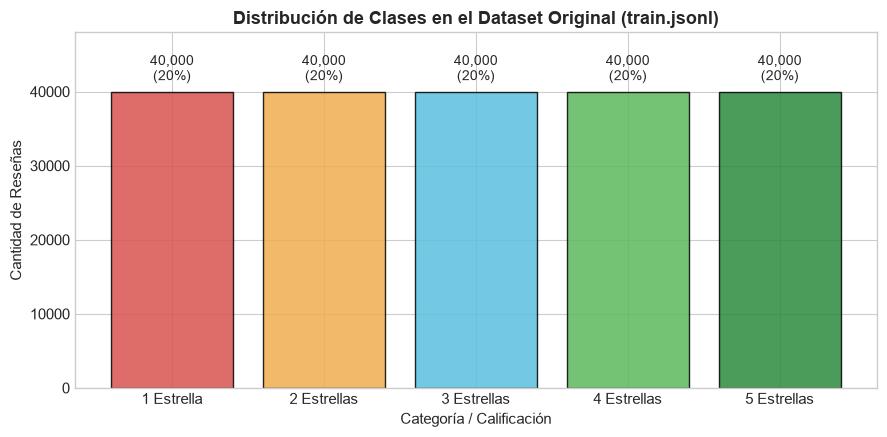

In [6]:
conteo_etiquetas = df['label'].value_counts().sort_index()
porcentaje_etiquetas = df['label'].value_counts(normalize=True).sort_index() * 100

resumen_etiquetas = pd.DataFrame({
    'Estrellas': ['1 Estrella', '2 Estrellas', '3 Estrellas', '4 Estrellas', '5 Estrellas'],
    'Etiqueta': conteo_etiquetas.index,
    'Cantidad': conteo_etiquetas.values,
    'Porcentaje (%)': porcentaje_etiquetas.values
})

print(resumen_etiquetas.to_string(index=False))

# Gráfico de barras
colores = ['#d9534f', '#f0ad4e', '#5bc0de', '#5cb85c', '#2b8a3e']
plt.figure(figsize=(9, 4.5))
bars = plt.bar(resumen_etiquetas['Estrellas'], resumen_etiquetas['Cantidad'], color=colores, edgecolor='black', alpha=0.85)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1000, f"{yval:,}\n(20%)", ha='center', va='bottom', fontsize=10)

plt.title('Distribución de Clases en el Dataset Original (train.jsonl)', fontsize=13, weight='bold')
plt.xlabel('Categoría / Calificación', fontsize=11)
plt.ylabel('Cantidad de Reseñas', fontsize=11)
plt.ylim(0, 48000)
plt.tight_layout()
plt.show()


## 5. Análisis de Longitud de las Reseñas

Analizamos la extensión de las opiniones tanto en **caracteres** como en **palabras** para dimensionar los requerimientos de tokenización y vectorización.


In [7]:
# Calcular longitudes
df['char_len'] = df['text'].str.len()
df['word_len'] = df['text'].str.split().str.len()

print("--- Estadísticas de Longitud en Caracteres ---")
print(df['char_len'].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]))

print("\n--- Estadísticas de Longitud en Palabras ---")
print(df['word_len'].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]))


--- Estadísticas de Longitud en Caracteres ---
count    200000.000000
mean        151.302910
std         132.201785
min          16.000000
5%           29.000000
25%          68.000000
50%         120.000000
75%         186.000000
95%         391.000000
max        3086.000000
Name: char_len, dtype: float64

--- Estadísticas de Longitud en Palabras ---
count    200000.000000
mean         27.799670
std          24.173565
min           2.000000
5%            5.000000
25%          13.000000
50%          22.000000
75%          34.000000
95%          72.000000
max         551.000000
Name: word_len, dtype: float64


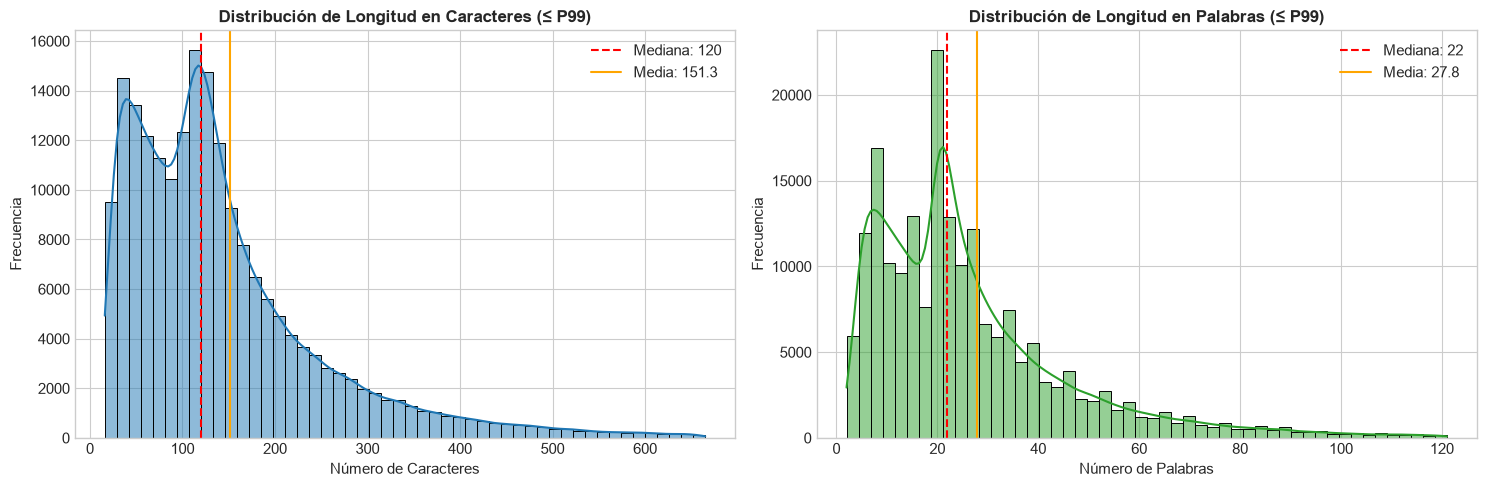

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distribución de caracteres (acotada al percentil 99 para mejor visualización)
p99_char = df['char_len'].quantile(0.99)
sns.histplot(df[df['char_len'] <= p99_char]['char_len'], bins=50, kde=True, ax=axes[0], color='#1f77b4')
axes[0].axvline(df['char_len'].median(), color='red', linestyle='--', label=f"Mediana: {df['char_len'].median():.0f}")
axes[0].axvline(df['char_len'].mean(), color='orange', linestyle='-', label=f"Media: {df['char_len'].mean():.1f}")
axes[0].set_title('Distribución de Longitud en Caracteres (≤ P99)', fontsize=12, weight='bold')
axes[0].set_xlabel('Número de Caracteres')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()

# Distribución de palabras (acotada al percentil 99)
p99_words = df['word_len'].quantile(0.99)
sns.histplot(df[df['word_len'] <= p99_words]['word_len'], bins=50, kde=True, ax=axes[1], color='#2ca02c')
axes[1].axvline(df['word_len'].median(), color='red', linestyle='--', label=f"Mediana: {df['word_len'].median():.0f}")
axes[1].axvline(df['word_len'].mean(), color='orange', linestyle='-', label=f"Media: {df['word_len'].mean():.1f}")
axes[1].set_title('Distribución de Longitud en Palabras (≤ P99)', fontsize=12, weight='bold')
axes[1].set_xlabel('Número de Palabras')
axes[1].set_ylabel('Frecuencia')
axes[1].legend()

plt.tight_layout()
plt.show()


In [9]:
# ¿Las opiniones negativas son más largas que las positivas?
longitud_por_clase = df.groupby('label')[['char_len', 'word_len']].agg(['mean', 'median', 'std'])
print("Resumen de longitud por etiqueta:")
longitud_por_clase


Resumen de longitud por etiqueta:


char_len                      word_len                  
             mean median         std       mean median        std
label                                                            
0      152.883475  121.0  126.669562  28.470575   22.0  23.191514
1      168.438750  131.0  139.441270  31.293075   24.0  25.470934
2      155.380300  123.0  133.936289  28.822900   23.0  24.645648
3      142.357200  116.0  126.397453  25.878525   21.0  23.109936
4      137.454825  110.0  131.906959  24.533275   20.0  23.784678

C:\Users\Usuario\AppData\Local\Temp\ipykernel_13296\3322395657.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label', y='word_len', data=df, showfliers=False, palette='Blues')
C:\Users\Usuario\AppData\Local\Temp\ipykernel_13296\3322395657.py:7: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()
D:\UAGRM\999 TOPICOS AVANZADOS DE PROGRAMACION\CritiqAI\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


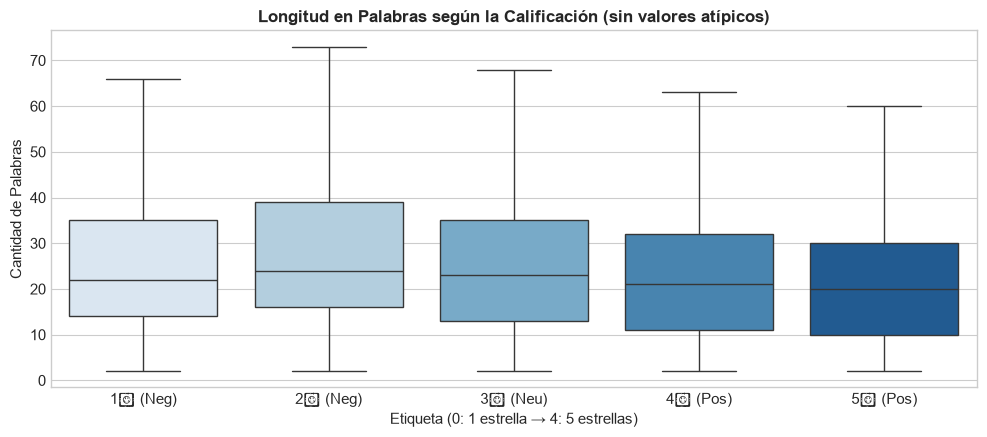

In [10]:
plt.figure(figsize=(10, 4.5))
sns.boxplot(x='label', y='word_len', data=df, showfliers=False, palette='Blues')
plt.title('Longitud en Palabras según la Calificación (sin valores atípicos)', fontsize=12, weight='bold')
plt.xlabel('Etiqueta (0: 1 estrella → 4: 5 estrellas)')
plt.ylabel('Cantidad de Palabras')
plt.xticks(ticks=[0, 1, 2, 3, 4], labels=['1★ (Neg)', '2★ (Neg)', '3★ (Neu)', '4★ (Pos)', '5★ (Pos)'])
plt.tight_layout()
plt.show()


## 6. Análisis Léxico y Palabras Frecuentes (Sin Procesar)

Examinamos las palabras más frecuentes para entender el vocabulario bruto antes de la aplicación de técnicas NLP.


C:\Users\Usuario\AppData\Local\Temp\ipykernel_13296\628131964.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frecuencia', y='Palabra', data=top30_global, palette='viridis')


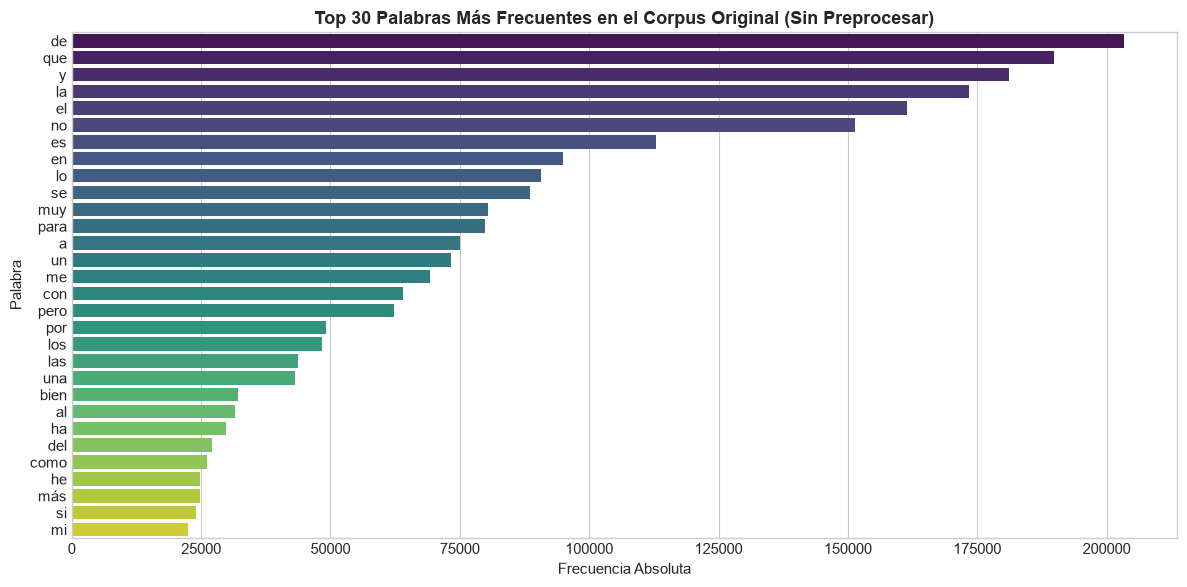

In [11]:
# Conteo de términos en todo el dataset
palabras_todas = ' '.join(df['text']).lower().split()
conteo_global = Counter(palabras_todas)

top30_global = pd.DataFrame(conteo_global.most_common(30), columns=['Palabra', 'Frecuencia'])

plt.figure(figsize=(12, 6))
sns.barplot(x='Frecuencia', y='Palabra', data=top30_global, palette='viridis')
plt.title('Top 30 Palabras Más Frecuentes en el Corpus Original (Sin Preprocesar)', fontsize=13, weight='bold')
plt.xlabel('Frecuencia Absoluta')
plt.tight_layout()
plt.show()


C:\Users\Usuario\AppData\Local\Temp\ipykernel_13296\4114631856.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frecuencia_Neg', y='Palabra', data=top15_neg, ax=axes[0], palette='Reds_r')
C:\Users\Usuario\AppData\Local\Temp\ipykernel_13296\4114631856.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frecuencia_Pos', y='Palabra', data=top15_pos, ax=axes[1], palette='Greens_r')


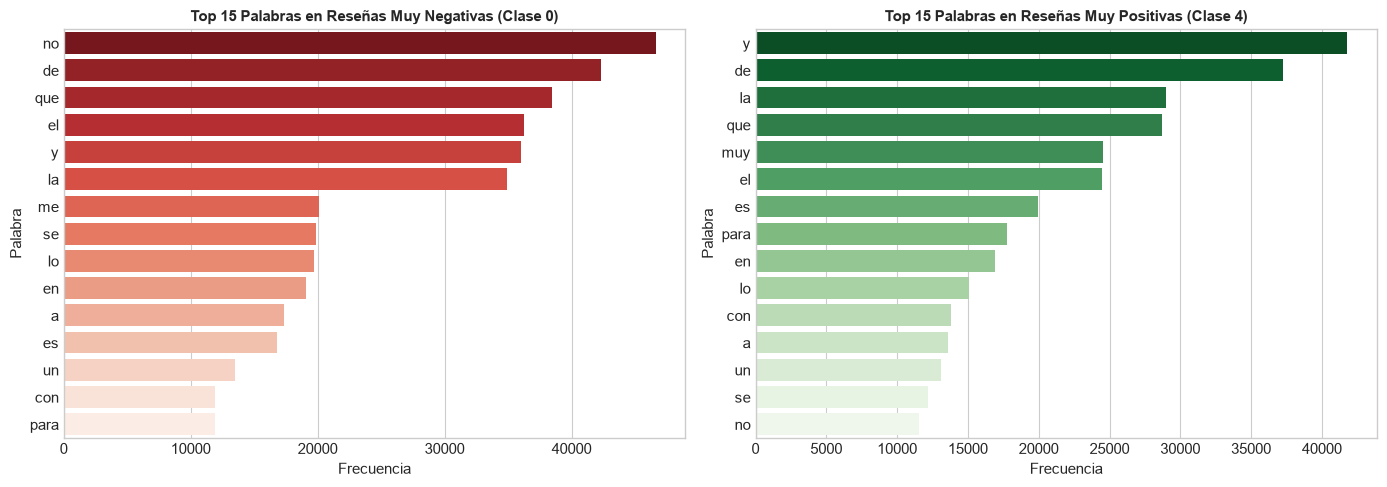

In [12]:
# Comparación directa entre clases extremas: 0 (muy negativa) vs 4 (muy positiva)
palabras_neg = ' '.join(df[df['label'] == 0]['text']).lower().split()
palabras_pos = ' '.join(df[df['label'] == 4]['text']).lower().split()

conteo_neg = Counter(palabras_neg)
conteo_pos = Counter(palabras_pos)

top15_neg = pd.DataFrame(conteo_neg.most_common(15), columns=['Palabra', 'Frecuencia_Neg'])
top15_pos = pd.DataFrame(conteo_pos.most_common(15), columns=['Palabra', 'Frecuencia_Pos'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x='Frecuencia_Neg', y='Palabra', data=top15_neg, ax=axes[0], palette='Reds_r')
axes[0].set_title('Top 15 Palabras en Reseñas Muy Negativas (Clase 0)', fontsize=11, weight='bold')
axes[0].set_xlabel('Frecuencia')

sns.barplot(x='Frecuencia_Pos', y='Palabra', data=top15_pos, ax=axes[1], palette='Greens_r')
axes[1].set_title('Top 15 Palabras en Reseñas Muy Positivas (Clase 4)', fontsize=11, weight='bold')
axes[1].set_xlabel('Frecuencia')

plt.tight_layout()
plt.show()


In [13]:
# Observación crítica sobre palabras de negación e intensificadores
terminos_clave = ['no', 'nunca', 'jamas', 'sin', 'muy', 'pero', 'bien', 'mal', 'excelente', 'pesimo']

frecuencias_por_clase = []
for termino in terminos_clave:
    fila = {'Término': termino}
    for lbl in range(5):
        c = Counter(' '.join(df[df['label'] == lbl]['text']).lower().split())
        fila[f'Clase {lbl}'] = c[termino]
    frecuencias_por_clase.append(fila)

pd.DataFrame(frecuencias_por_clase)


,Término,Clase 0,Clase 1,Clase 2,Clase 3,Clase 4
0,no,46621,42284,32050,18808,11534
1,nunca,1635,330,219,133,257
2,jamas,49,3,4,1,4
3,sin,3538,3373,2903,2815,3301
4,muy,9322,13434,14303,18889,24521
5,pero,8373,16526,19353,12480,5461
6,bien,2807,6041,8414,8586,6239
7,mal,2154,1725,1323,463,134
8,excelente,39,49,90,344,795
9,pesimo,38,12,5,1,0


## 7. Conclusiones y Decisiones para el Pipeline NLP

1. **Balance de datos:** El dataset original está completamente equilibrado (40.000 ejemplos por cada una de las 5 clases). La transformación binaria producirá 80.000 negativas (clases 0 y 1) y 80.000 positivas (clases 3 y 4), manteniendo un balance perfecto (50/50).
2. **Calidad de datos:** No hay nulos ni valores vacíos. Los identificadores son únicos. No se requiere imputación de datos.
3. **Longitud textual:** La mediana es de 22 palabras (120 caracteres). Las opiniones negativas tienden a ser ligeramente más extensas (media de ~31 palabras vs ~22 palabras en positivas), ya que los clientes insatisfechos detallan minuciosamente los fallos del producto o entrega.
4. **Tratamiento crítico de Stopwords:** La palabra `"no"` es el término más frecuente en las opiniones negativas (46.621 apariciones en clase 0 frente a sólo 11.534 en clase 4). **Eliminar `"no"`, `"nunca"`, `"jamás"` o `"sin"` destruiría la señal de sentimiento.** Por tanto, la lista de stopwords del pipeline debe preservar estrictamente los modificadores y negaciones.
5. **N-gramas:** La alta frecuencia de expresiones como *"buena relación calidad precio"* o *"no funciona"* justifica la extracción de bigramas (`ngram_range=(1,2)`) para capturar contexto sintáctico que los unigramas aislados pierden.
